In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Plotting a volume on slices

How to cite this: see [Citations](../citations.qmd).

A volume is a 3D array with one value per atlas voxel. This page builds one, plots it on coronal, sagittal and horizontal slices, and shows how its shape follows the atlas resolution. The same calls work for any volume you have, such as an image stack registered to the atlas, or one value per voxel from your own analysis.

## A volume matches the atlas image

The volume must have the same shape as the atlas image, indexed (AP, ML, DV). Voxels set to `NaN`, such as those outside the brain, are left unpainted so the background shows through.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from iblatlas.atlas import AllenAtlas

ba = AllenAtlas(res_um=50)
ba.image.shape

(264, 228, 160)

As an example, this volume is a smooth blob centred in the left thalamus, built from the voxel coordinates of the atlas (in metres from bregma).

In [3]:
ap, ml, dv = np.meshgrid(ba.bc.yscale, ba.bc.xscale, ba.bc.zscale, indexing='ij')
distance_sq = (ap - (-0.0015)) ** 2 + (ml - (-0.002)) ** 2 + (dv - (-0.003)) ** 2
volume = np.exp(-distance_sq / (2 * 0.001 ** 2)).astype(np.float32)

# leave voxels outside the brain, and voxels with almost no signal, unpainted
volume[(ba.label == 0) | (volume < 0.02)] = np.nan

assert volume.shape == ba.image.shape

## Plot a slice

`plot_volume_on_slice` takes the volume, the slice orientation (`'coronal'`, `'sagittal'` or `'horizontal'`) and the position of the slice in micrometres.

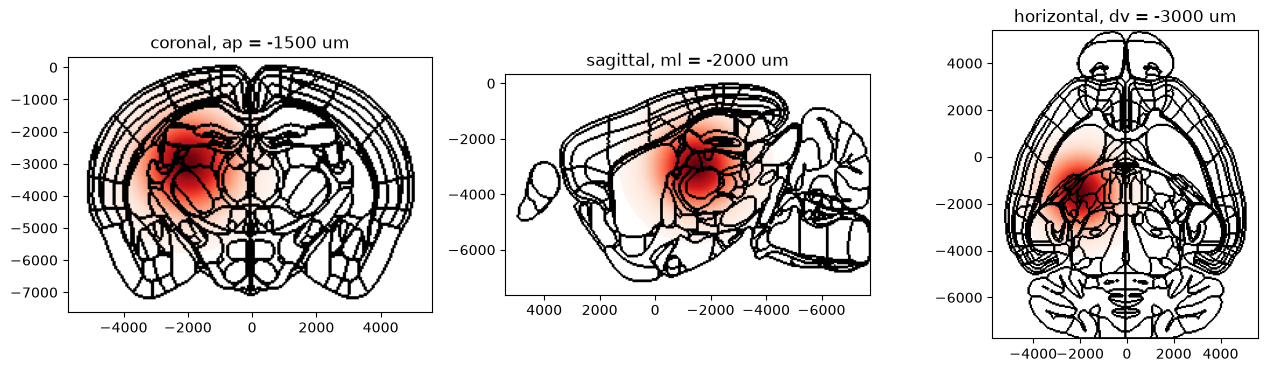

In [4]:
from iblatlas.plots import plot_volume_on_slice

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
plot_volume_on_slice(volume, coord=-1500, slice='coronal', brain_atlas=ba, ax=axs[0])
plot_volume_on_slice(volume, coord=-2000, slice='sagittal', brain_atlas=ba, ax=axs[1])
plot_volume_on_slice(volume, coord=-3000, slice='horizontal', brain_atlas=ba, ax=axs[2])
axs[0].set_title('coronal, ap = -1500 um')
axs[1].set_title('sagittal, ml = -2000 um')
axs[2].set_title('horizontal, dv = -3000 um');

## Colours, background and region boundaries

- `cmap` and `clevels` set the colormap and its limits, and `show_cbar=True` adds a colour bar. With a colour bar the function also returns the colorbar.
- `background` is `'boundary'` (region outlines, the default) or `'image'` (the atlas template image).
- `mapping` sets the regions that the boundaries outline: `'Allen'`, `'Beryl'` or `'Cosmos'`. See [Brain region mappings](../explanation/brain-region-mappings.qmd).

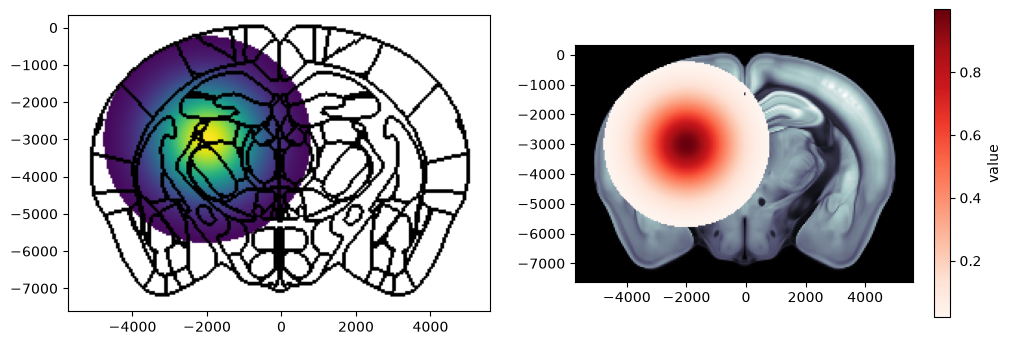

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plot_volume_on_slice(volume, coord=-1500, slice='coronal', mapping='Beryl', background='boundary',
                     cmap='viridis', clevels=[0, 1], brain_atlas=ba, ax=axs[0])
fig, ax, cbar = plot_volume_on_slice(volume, coord=-1500, slice='coronal', background='image',
                                     cmap='Reds', show_cbar=True, brain_atlas=ba, ax=axs[1])
cbar.set_label('value')

## Resolution

The atlas is available at 10, 25 and 50 um. A volume has to be built for the resolution of the atlas it is plotted on: the same blob has a different shape at each, and a mismatch raises an assertion error.

In [6]:
for res_um in (25, 50):
    print(res_um, AllenAtlas(res_um=res_um).image.shape)

25 (528, 456, 320)
50 (264, 228, 160)


Pass the atlas you built the volume for as `brain_atlas`. If you leave it out, the function loads the default 25 um atlas, so a volume made at another resolution will not match.

## Where a volume comes from

- **From points.** `compute_volume_from_points` places points in their voxels, aggregates the points that share a voxel (sum, count, mean and others) and can smooth the result. See [Plotting cluster locations on histology slices](plot-points-on-slices.ipynb).
- **From a loaded dataset.** The gene expression, lipid and MERFISH how-tos load volumes that are already in the atlas space: [gene expression](load-gene-expression-agea.ipynb), [lipids](load-lipids.ipynb) and [MERFISH](load-merfish.ipynb).